# Hybrid Twin — Data Preprocessing Pipeline

**Pipeline Overview:**
1. [Imports & Configuration](#1)
2. [Generate & Load Data](#2)
3. [Exploratory Data Analysis (EDA)](#3)
4. [Outlier Detection & Handling](#4)
5. [Train / Validation / Test Split](#5)
6. [Normalization / Scaling](#6)
7. [Save Preprocessed Data](#7)

<a id='1'></a>
## 1 · Imports & Configuration

In [1]:
import sys, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

PROJECT_ROOT = os.path.abspath('..')
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

from hybrid_twin.config.loader import load_config 

cfg = load_config(Path(PROJECT_ROOT) / "config.yaml")

N_SIMULATIONS  = cfg["simulation"]["N_SIMULATIONS"]
SEQ_LENGTH     = cfg["simulation"]["SEQ_LENGTH"]
Ak_modes       = cfg["simulation"]["AK_MODES"]
mapping_matrix = cfg["simulation"]["MAPPING_MATRIX"]
OUTPUT_PATH    = cfg["paths"]["DATA_DIR"]

# Aesthetics
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)
plt.rcParams.update({'figure.dpi': 120, 'axes.titleweight': 'bold', 'axes.titlesize': 13})

# Reproducibility
np.random.seed(cfg["simulation"]["SEED"])

os.makedirs(OUTPUT_PATH, exist_ok=True)

N_FEATURES    = 4        # [Fx, Fy, Fz, sigma_sim]
FEATURE_COLS  = ['Fx', 'Fy', 'Fz', 'sigma_sim']
TARGET_COL    = 'delta'

print('Configuration OK')

Configuration OK


<a id='2'></a>
## 2 · Generate & Load Data

We call `generate_data()` directly from our module to get the 3-D arrays
`X : (N_SIMULATIONS, SEQ_LENGTH, 4)` and `y : (N_SIMULATIONS,)`.
These are the native inputs for an LSTM Bias Learner.

In [2]:
from hybrid_twin.data.generate_data import generate_data 
from hybrid_twin.data.get_data import get_data 

X, y, df_summary = generate_data(N_SIMULATIONS, SEQ_LENGTH, Ak_modes, mapping_matrix)

# dataset_path = "../dataset/hybrid_twin_dataset.csv"
# X, y, df_summary = get_data(file_path=dataset_path,seq_length=SEQ_LENGTH)

print(f'X shape : {X.shape}  → (simulations, timesteps, features)')
print(f'y shape : {y.shape}  → (simulations,) — bias delta at last timestep')
print(f'\nFeature order: {FEATURE_COLS}')
print(f'Target       : {TARGET_COL}  (= sigma_real - sigma_sim at t=T_final)')

Generating 1000 sequences of length 100...
X shape : (1000, 100, 4)  → (simulations, timesteps, features)
y shape : (1000, 100)  → (simulations,) — bias delta at last timestep

Feature order: ['Fx', 'Fy', 'Fz', 'sigma_sim']
Target       : delta  (= sigma_real - sigma_sim at t=T_final)


In [3]:
# Quick look at the CSV summary (last timestep of each simulation)
print(f'CSV summary shape: {df_summary.shape}')
df_summary.describe().round(4)

CSV summary shape: (100000, 8)


,simulation_id,timestep,Fx,Fy,Fz,sigma_sim,sigma_real,delta
count,100000.0000,100000.0000,100000.0000,100000.0000,100000.0000,100000.0000,100000.0000,100000.0000
mean,499.5000,49.5000,0.0282,0.0133,-0.0172,-0.0042,-0.0055,-0.0013
std,288.6764,28.8662,0.7094,0.7216,0.7386,0.6571,0.7325,0.1226
min,0.0000,0.0000,-3.1890,-3.3214,-3.6270,-3.2661,-1.9581,-0.9654
25%,249.7500,24.7500,-0.3733,-0.3910,-0.4415,-0.3857,-0.5036,-0.1068
50%,499.5000,49.5000,0.0201,0.0090,-0.0183,-0.0076,-0.0096,-0.0017
75%,749.2500,74.2500,0.4154,0.4202,0.3941,0.3681,0.4819,0.1020
max,999.0000,99.0000,3.7103,3.4026,3.6644,2.8821,1.9218,1.3227


<a id='3'></a>
## 3 · Exploratory Data Analysis

Because our data is temporal, we look at:
- **A few example sequences** to understand the signal shapes
- **Distribution of the target** `delta` across all simulations
- **Correlation** between features at the last timestep

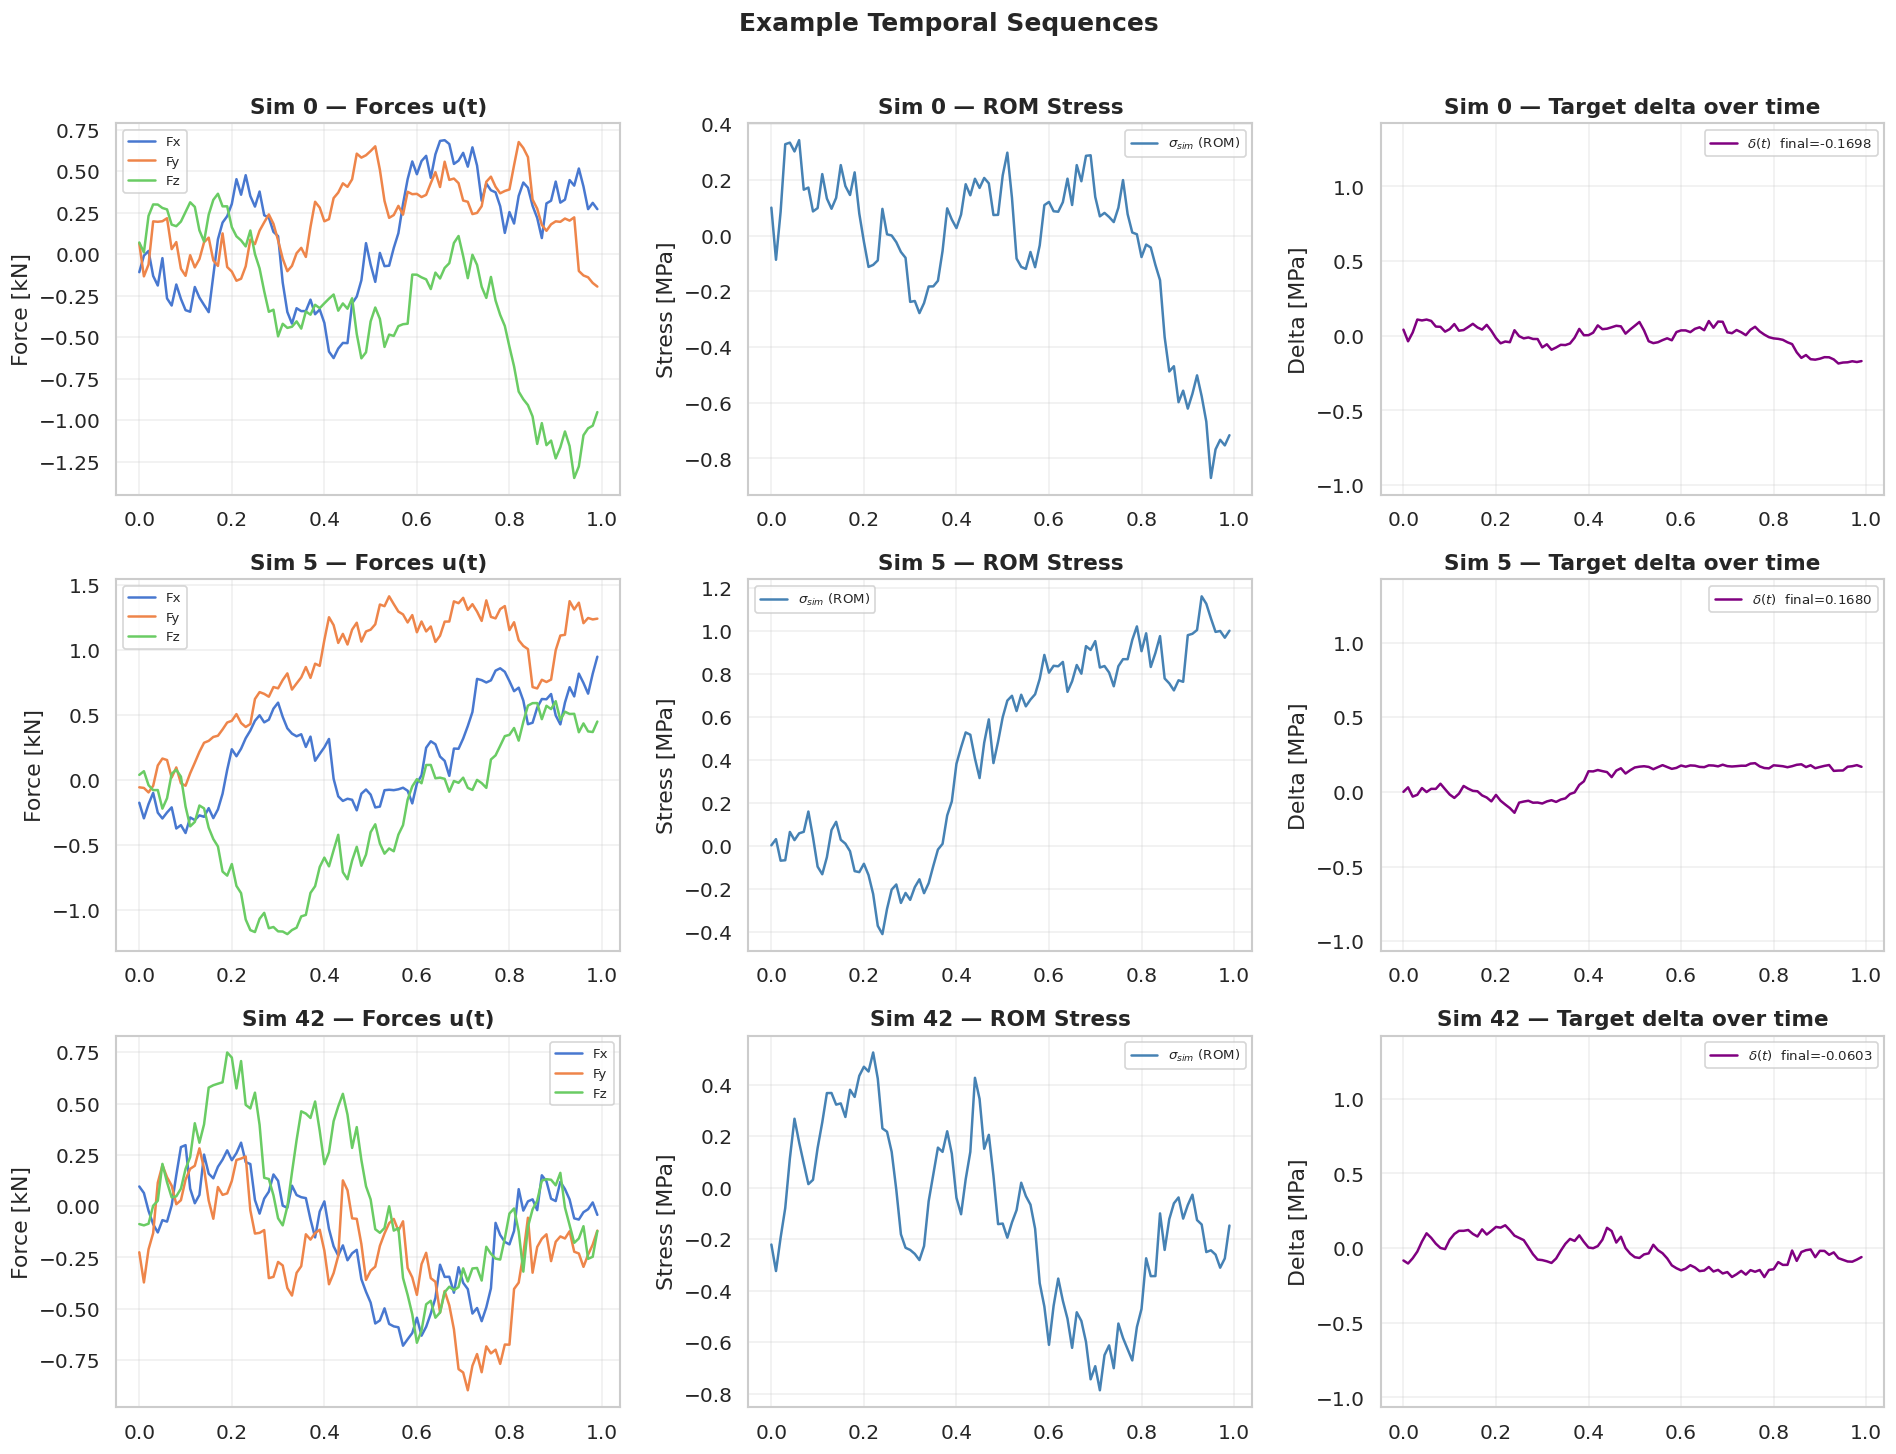

In [4]:
# --- Plot 3 simulations ---
PLOT_INDICES = [0, 5, 42]
t = np.arange(SEQ_LENGTH) * 0.01   # time axis in seconds
fig, axes = plt.subplots(len(PLOT_INDICES), 3, figsize=(16, 4 * len(PLOT_INDICES)))

for row, idx in enumerate(PLOT_INDICES):
    forces  = X[idx, :, :3]   # (SEQ_LENGTH, 3)
    sig_sim = X[idx, :,  3]   # (SEQ_LENGTH,)
    delta_t = y[idx]           # (SEQ_LENGTH,)  ← full sequence now

    # Forces
    ax = axes[row, 0]
    for j, label in enumerate(['Fx', 'Fy', 'Fz']):
        ax.plot(t, forces[:, j], label=label)
    ax.set_title(f'Sim {idx} — Forces u(t)')
    ax.set_ylabel('Force [kN]')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

    # sigma_sim
    ax = axes[row, 1]
    ax.plot(t, sig_sim, color='steelblue', label=r'$\sigma_{sim}$ (ROM)')
    ax.set_title(f'Sim {idx} — ROM Stress')
    ax.set_ylabel('Stress [MPa]')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

    # Target delta — now a full time series, not a scalar
    ax = axes[row, 2]
    ax.plot(t, delta_t, color='purple', linewidth=1.5,
            label=fr'$\delta(t)$  final={delta_t[-1]:.4f}')
    ax.set_title(f'Sim {idx} — Target delta over time')
    ax.set_ylabel('Delta [MPa]')
    ax.set_ylim(y.min() - 0.1, y.max() + 0.1)
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

plt.suptitle('Example Temporal Sequences', fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

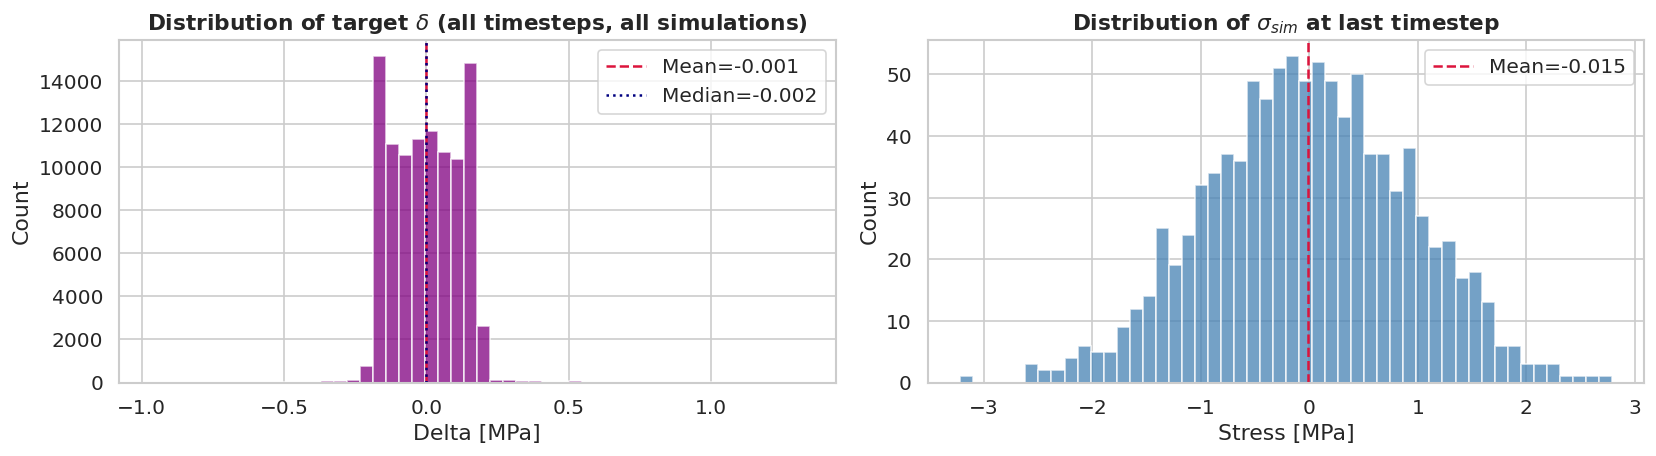

In [5]:
# --- Distribution of the target delta across all simulations ---
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

ax = axes[0]
y_flat = y.flatten()   # (N*T,)  ← flatten so hist sees one dataset
ax.hist(y_flat, bins=50, color='purple', alpha=0.75, edgecolor='white')
ax.axvline(y_flat.mean(),   color='crimson', linestyle='--', linewidth=1.5,
           label=f'Mean={y_flat.mean():.3f}')
ax.axvline(np.median(y_flat), color='navy', linestyle=':', linewidth=1.5,
           label=f'Median={np.median(y_flat):.3f}')
ax.set_title(r'Distribution of target $\delta$ (all timesteps, all simulations)')
ax.set_xlabel('Delta [MPa]')
ax.set_ylabel('Count')
ax.legend()

# --- Distribution of sigma_sim at last timestep ---
sigma_sim_last = X[:, -1, 3]   # (N,) — still a scalar per sim, no change needed
ax = axes[1]
ax.hist(sigma_sim_last, bins=50, color='steelblue', alpha=0.75, edgecolor='white')
ax.axvline(sigma_sim_last.mean(), color='crimson', linestyle='--', linewidth=1.5,
           label=f'Mean={sigma_sim_last.mean():.3f}')
ax.set_title(r'Distribution of $\sigma_{sim}$ at last timestep')
ax.set_xlabel('Stress [MPa]')
ax.set_ylabel('Count')
ax.legend()

plt.tight_layout()
plt.show()

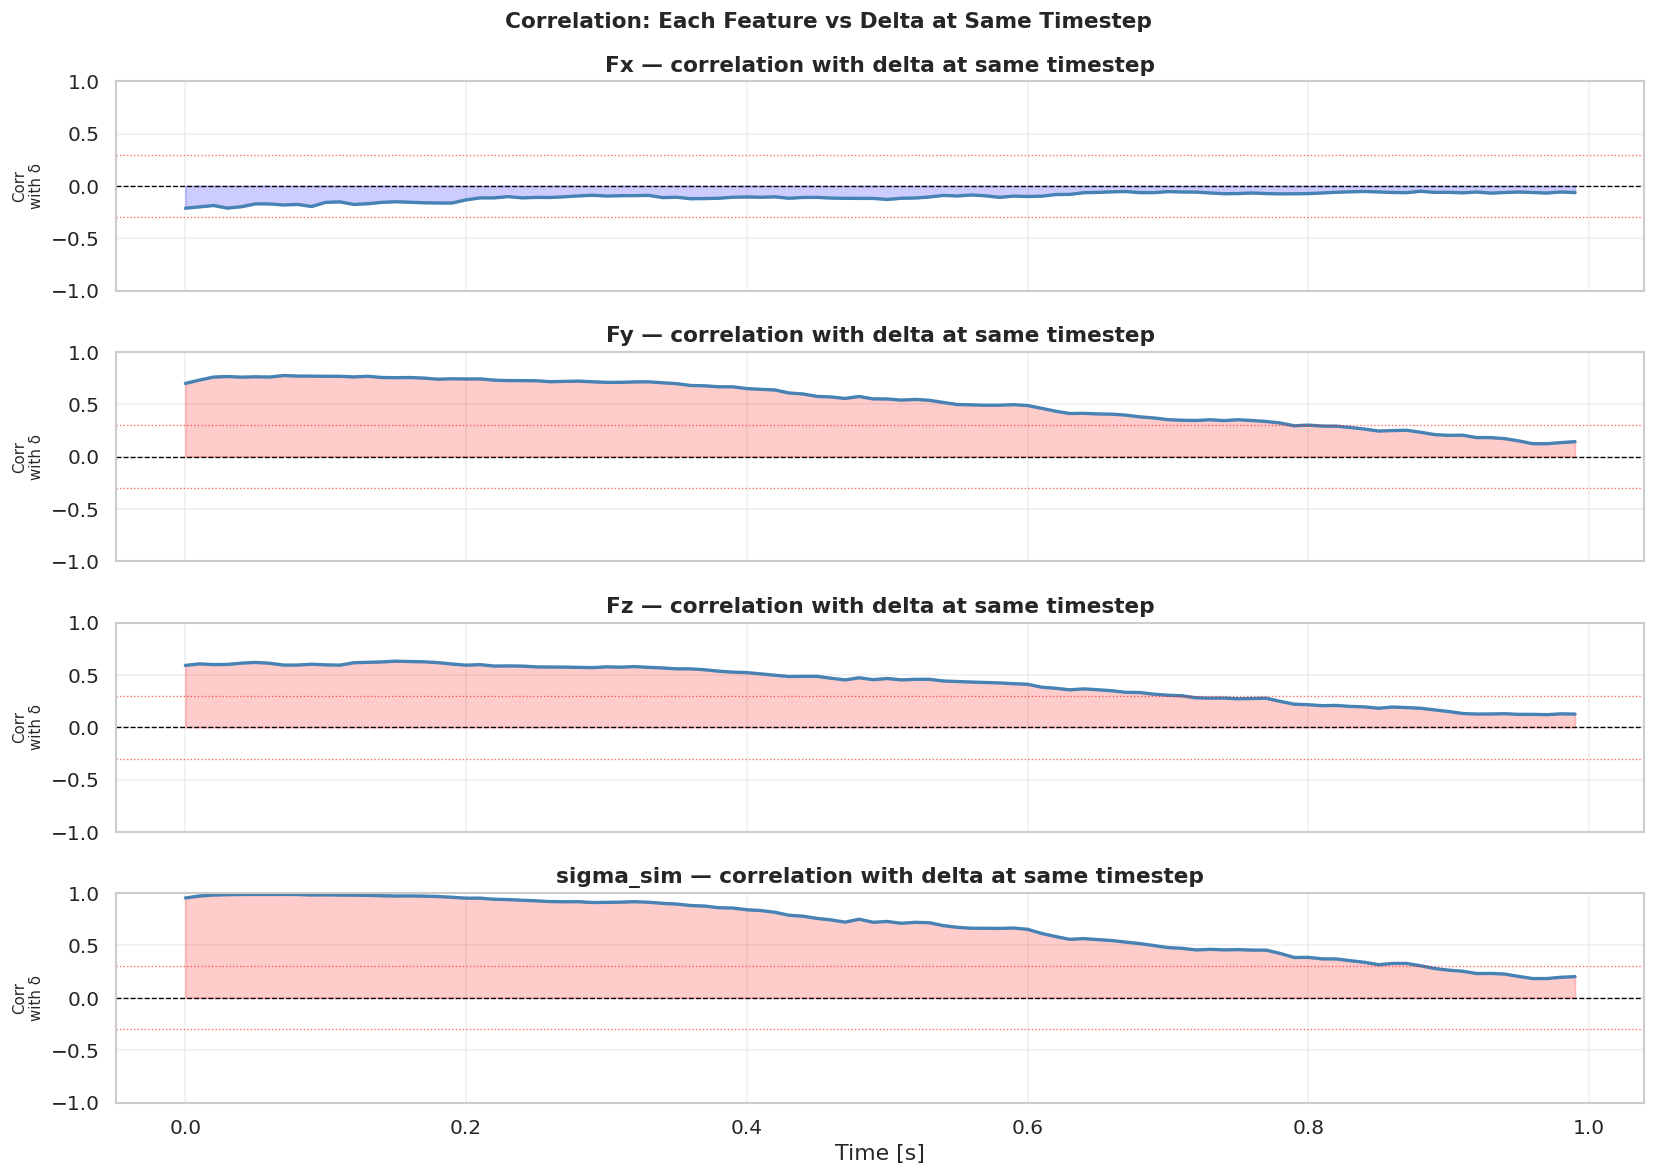

In [6]:
import numpy as np
import matplotlib.pyplot as plt

FEATURE_COLS = ['Fx', 'Fy', 'Fz', 'sigma_sim']
t = np.arange(SEQ_LENGTH) * 0.01

# y is now (N, T) — correlate feature at timestep t with delta at same timestep t
corr_matrix = np.zeros((len(FEATURE_COLS), SEQ_LENGTH))  # (4, 100)

for f_idx in range(len(FEATURE_COLS)):
    for t_idx in range(SEQ_LENGTH):
        feature_values = X[:, t_idx, f_idx]   # (N,) — all sims at timestep t
        delta_values   = y[:, t_idx]           # (N,) — delta at same timestep  ← fix
        corr_matrix[f_idx, t_idx] = np.corrcoef(feature_values, delta_values)[0, 1]

# ── Plot ───────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(len(FEATURE_COLS), 1, figsize=(14, 10), sharex=True)

for f_idx, (ax, fname) in enumerate(zip(axes, FEATURE_COLS)):
    ax.plot(t, corr_matrix[f_idx], linewidth=2, color='steelblue')
    ax.axhline(0,    color='black', linewidth=0.8, linestyle='--')
    ax.axhline( 0.3, color='red',   linewidth=0.8, linestyle=':', alpha=0.6)
    ax.axhline(-0.3, color='red',   linewidth=0.8, linestyle=':', alpha=0.6)
    ax.fill_between(t, corr_matrix[f_idx], 0,
                    where=corr_matrix[f_idx] > 0, alpha=0.2, color='red')
    ax.fill_between(t, corr_matrix[f_idx], 0,
                    where=corr_matrix[f_idx] < 0, alpha=0.2, color='blue')
    ax.set_ylabel('Corr\nwith δ', fontsize=9)
    ax.set_title(f'{fname} — correlation with delta at same timestep')
    ax.set_ylim(-1, 1)
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel('Time [s]')
plt.suptitle('Correlation: Each Feature vs Delta at Same Timestep',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

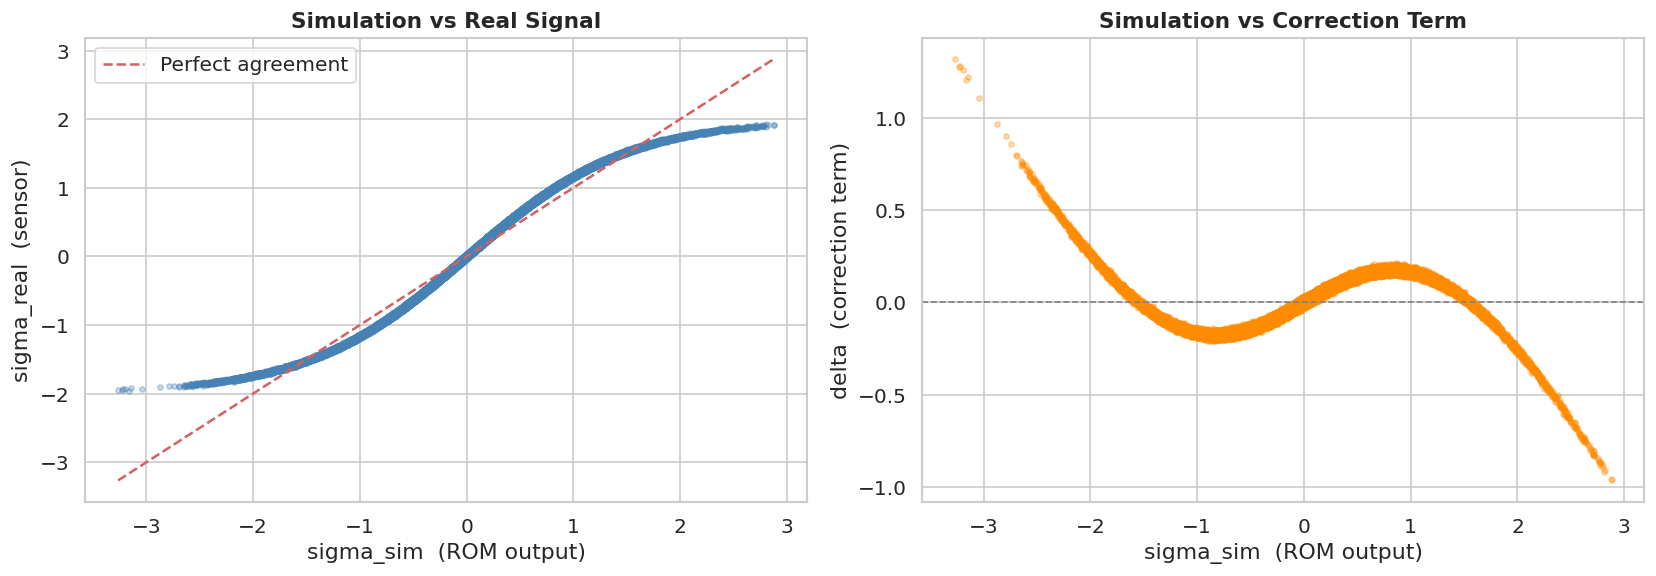

In [7]:
# --- Scatter: sigma_sim vs sigma_real and vs delta ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
ax.scatter(df_summary['sigma_sim'], df_summary['sigma_real'],
           alpha=0.3, s=10, color='steelblue')
lims = [min(df_summary['sigma_sim'].min(), df_summary['sigma_real'].min()),
        max(df_summary['sigma_sim'].max(), df_summary['sigma_real'].max())]
ax.plot(lims, lims, 'r--', linewidth=1.5, label='Perfect agreement')
ax.set_xlabel('sigma_sim  (ROM output)')
ax.set_ylabel('sigma_real  (sensor)')
ax.set_title('Simulation vs Real Signal')
ax.legend()

ax = axes[1]
ax.scatter(df_summary['sigma_sim'], df_summary['delta'],
           alpha=0.3, s=10, color='darkorange')
ax.axhline(0, color='grey', linestyle='--', linewidth=1)
ax.set_xlabel('sigma_sim  (ROM output)')
ax.set_ylabel('delta  (correction term)')
ax.set_title('Simulation vs Correction Term')

plt.tight_layout()
plt.show()

<a id='4'></a>
## 4 · Outlier Detection & Handling

We use **IQR** on the target `y` (delta at last timestep).
Shocks are physically rare but real — we **clip** rather than drop sequences.

In [8]:
def iqr_outlier_report(values, name, threshold=1.5):
    Q1, Q3 = np.percentile(values, [25, 75])
    IQR = Q3 - Q1
    lo, hi = Q1 - threshold * IQR, Q3 + threshold * IQR
    n_out = np.sum((values < lo) | (values > hi))
    print(f'{name}: Q1={Q1:.3f}  Q3={Q3:.3f}  IQR={IQR:.3f}')
    print(f'  Fences: [{lo:.3f}, {hi:.3f}]')
    print(f'  Outliers: {n_out} / {len(values)}  ({100*n_out/len(values):.1f}%)')
    return lo, hi

lo_y, hi_y = iqr_outlier_report(y, 'delta (y)')

delta (y): Q1=-0.107  Q3=0.102  IQR=0.209
  Fences: [-0.420, 0.415]
  Outliers: 367 / 1000  (36.7%)


Clipped 367 target values in y (out of 100000 total)


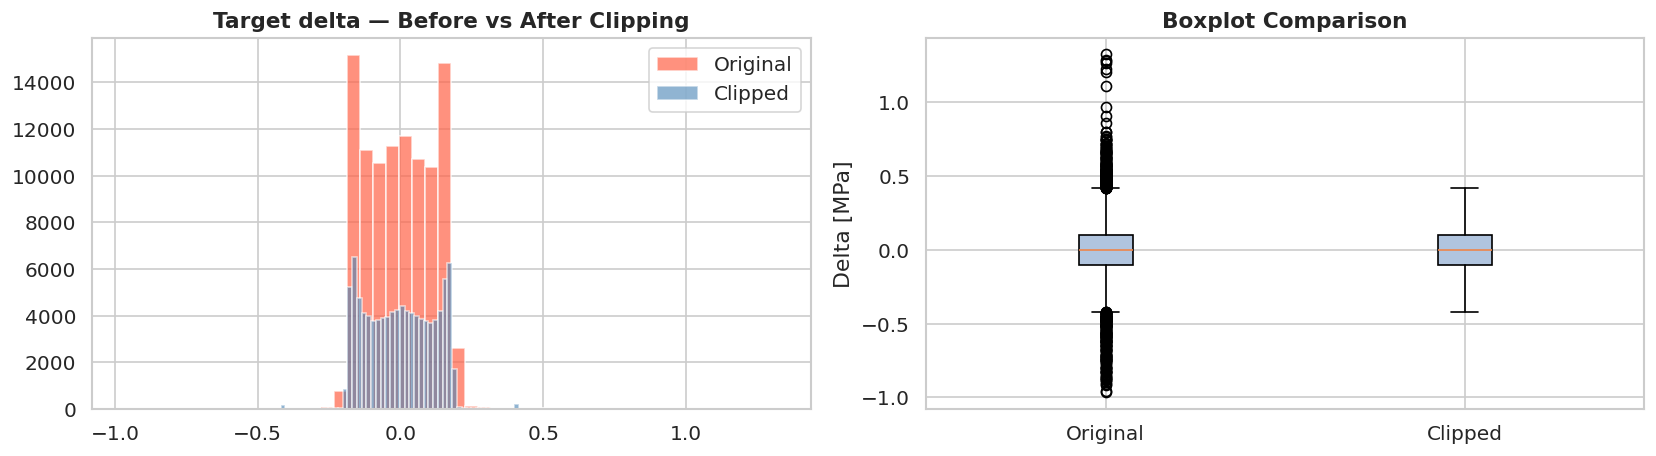

In [9]:
# Clip target y — keep X sequences intact (physics is deterministic)
y_clean = np.clip(y, lo_y, hi_y)
X_clean = X.copy()

# y is (N, T) — count clipped values across all timesteps
n_clipped = np.sum((y < lo_y) | (y > hi_y))
print(f'Clipped {n_clipped} target values in y (out of {y.size} total)')

# Flatten for plotting — distributions over all timesteps & simulations
y_flat       = y.flatten()
y_clean_flat = y_clean.flatten()

# Before vs After
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].hist(y_flat,       bins=50, color='tomato',    alpha=0.7, edgecolor='white', label='Original')
axes[0].hist(y_clean_flat, bins=50, color='steelblue', alpha=0.6, edgecolor='white', label='Clipped')
axes[0].set_title('Target delta — Before vs After Clipping')
axes[0].legend()

axes[1].boxplot([y_flat, y_clean_flat], labels=['Original', 'Clipped'], patch_artist=True,
                boxprops=dict(facecolor='lightsteelblue'))
axes[1].set_title('Boxplot Comparison')
axes[1].set_ylabel('Delta [MPa]')

plt.tight_layout()
plt.show()

<a id='5'></a>
## 5 · Train / Validation / Test Split

We split **by simulation index** (not by row) so that each temporal sequence
stays intact. We use an **80 / 10 / 10** split.

In [10]:
n = len(X_clean)

# Shuffle indices
indices = np.random.permutation(n)

n_train = int(0.80 * n)
n_val   = int(0.10 * n)
# n_test  = remaining

train_idx = indices[:n_train]
val_idx   = indices[n_train:n_train + n_val]
test_idx  = indices[n_train + n_val:]

X_train, y_train = X_clean[train_idx], y_clean[train_idx]
X_val,   y_val   = X_clean[val_idx],   y_clean[val_idx]
X_test,  y_test  = X_clean[test_idx],  y_clean[test_idx]

print('Split summary (by simulation):')
print(f'  Train      : {len(X_train):>4} sequences  ({100*len(X_train)/n:.0f}%)  shape {X_train.shape}')
print(f'  Validation : {len(X_val):>4} sequences  ({100*len(X_val)/n:.0f}%)  shape {X_val.shape}')
print(f'  Test       : {len(X_test):>4} sequences  ({100*len(X_test)/n:.0f}%)  shape {X_test.shape}')

Split summary (by simulation):
  Train      :  800 sequences  (80%)  shape (800, 100, 4)
  Validation :  100 sequences  (10%)  shape (100, 100, 4)
  Test       :  100 sequences  (10%)  shape (100, 100, 4)


<a id='6'></a>
## 6 · Normalization / Scaling

The scaler is fit **only on the training set** to avoid data leakage.
We reshape to 2D for the scaler, then reshape back to 3D for the LSTM.

In [11]:
# Reshape (N, SEQ, 4) → (N*SEQ, 4) for the scaler
X_train_2d = X_train.reshape(-1, N_FEATURES)
X_val_2d   = X_val.reshape(-1, N_FEATURES)
X_test_2d  = X_test.reshape(-1, N_FEATURES)

scaler_X = StandardScaler()
scaler_y = StandardScaler()

# Fit ONLY on train, transform all
X_train_sc = scaler_X.fit_transform(X_train_2d).reshape(X_train.shape)   # back to 3D
X_val_sc   = scaler_X.transform(X_val_2d).reshape(X_val.shape)
X_test_sc  = scaler_X.transform(X_test_2d).reshape(X_test.shape)

y_train_sc = scaler_y.fit_transform(y_train.reshape(-1, 1)).ravel()
y_val_sc   = scaler_y.transform(y_val.reshape(-1, 1)).ravel()
y_test_sc  = scaler_y.transform(y_test.reshape(-1, 1)).ravel()

print('Scaling complete — fit on training set only.')
print(f'X_train scaled: mean={X_train_sc.mean():.4f}  std={X_train_sc.std():.4f}')
print(f'y_train scaled: mean={y_train_sc.mean():.4f}  std={y_train_sc.std():.4f}')
print(f'\nShapes after scaling:')
print(f'  X_train_sc : {X_train_sc.shape}   ← ready for LSTM input')
print(f'  y_train_sc : {y_train_sc.shape}')

Scaling complete — fit on training set only.
X_train scaled: mean=-0.0000  std=1.0000
y_train scaled: mean=0.0000  std=1.0000

Shapes after scaling:
  X_train_sc : (800, 100, 4)   ← ready for LSTM input
  y_train_sc : (80000,)


<a id='7'></a>
## 7 · Save Preprocessed Data

In [12]:
import joblib

# Save 3D numpy arrays
np.save(OUTPUT_PATH / 'X_train.npy', X_train_sc)
np.save(OUTPUT_PATH / 'X_val.npy',   X_val_sc)
np.save(OUTPUT_PATH / 'X_test.npy',  X_test_sc)
np.save(OUTPUT_PATH / 'y_train.npy', y_train_sc)
np.save(OUTPUT_PATH / 'y_val.npy',   y_val_sc)
np.save(OUTPUT_PATH / 'y_test.npy',  y_test_sc)

# Save scalers
joblib.dump(scaler_X, OUTPUT_PATH / 'scaler_X.pkl')
joblib.dump(scaler_y, OUTPUT_PATH / 'scaler_y.pkl')

# Save CSV
df_summary.to_csv(OUTPUT_PATH / 'dataset_engineered.csv', index=False)

print('All outputs saved to:', OUTPUT_PATH)
print()
print('Files saved:')
for f in ['X_train.npy', 'X_val.npy', 'X_test.npy',
          'y_train.npy', 'y_val.npy', 'y_test.npy',
          'scaler_X.pkl', 'scaler_y.pkl', 'dataset_engineered.csv']:
    path = OUTPUT_PATH / f
    size = os.path.getsize(path) if os.path.exists(path) else 0
    print(f'  {f:<30} {size/1024:.1f} KB')

All outputs saved to: /home/aya/Desktop/Hybrid-Twin-restructured/dataset/data

Files saved:
  X_train.npy                    1250.1 KB
  X_val.npy                      156.4 KB
  X_test.npy                     156.4 KB
  y_train.npy                    625.1 KB
  y_val.npy                      78.2 KB
  y_test.npy                     78.2 KB
  scaler_X.pkl                   0.7 KB
  scaler_y.pkl                   0.6 KB
  dataset_engineered.csv         12352.0 KB


In [13]:
# Final sanity check — reload and verify shapes
print('Reload check:')
for name in ['X_train', 'X_val', 'X_test', 'y_train', 'y_val', 'y_test']:
    # Use the / operator to join paths safely
    file_path = OUTPUT_PATH / f'{name}.npy' 
    arr = np.load(file_path)
    print(f'  {name:<10} : {arr.shape}')

Reload check:
  X_train    : (800, 100, 4)
  X_val      : (100, 100, 4)
  X_test     : (100, 100, 4)
  y_train    : (80000,)
  y_val      : (10000,)
  y_test     : (10000,)
